In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
df=pd.read_csv('../data/processed-data/cleaned_data.csv')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7032 entries, 0 to 7031
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7032 non-null   str    
 1   SeniorCitizen     7032 non-null   int64  
 2   Partner           7032 non-null   int64  
 3   Dependents        7032 non-null   int64  
 4   tenure            7032 non-null   int64  
 5   PhoneService      7032 non-null   int64  
 6   MultipleLines     7032 non-null   str    
 7   InternetService   7032 non-null   str    
 8   OnlineSecurity    7032 non-null   str    
 9   OnlineBackup      7032 non-null   str    
 10  DeviceProtection  7032 non-null   str    
 11  TechSupport       7032 non-null   str    
 12  StreamingTV       7032 non-null   str    
 13  StreamingMovies   7032 non-null   str    
 14  Contract          7032 non-null   str    
 15  PaperlessBilling  7032 non-null   int64  
 16  PaymentMethod     7032 non-null   str    
 17  Monthl

In [4]:
#select numeric columns and categorical columns
df_num=df.select_dtypes(include=np.number)
df_cat=df.select_dtypes(include='object')

C:\Users\dell\AppData\Local\Temp\ipykernel_3944\2090132486.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df_cat=df.select_dtypes(include='object')


In [5]:
cols=['SeniorCitizen','Partner','Dependents','PhoneService','PaperlessBilling','Churn','tenure']

In [6]:
for col in cols:
    df[col]=df[col].astype('int8')

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7032 entries, 0 to 7031
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7032 non-null   str    
 1   SeniorCitizen     7032 non-null   int8   
 2   Partner           7032 non-null   int8   
 3   Dependents        7032 non-null   int8   
 4   tenure            7032 non-null   int8   
 5   PhoneService      7032 non-null   int8   
 6   MultipleLines     7032 non-null   str    
 7   InternetService   7032 non-null   str    
 8   OnlineSecurity    7032 non-null   str    
 9   OnlineBackup      7032 non-null   str    
 10  DeviceProtection  7032 non-null   str    
 11  TechSupport       7032 non-null   str    
 12  StreamingTV       7032 non-null   str    
 13  StreamingMovies   7032 non-null   str    
 14  Contract          7032 non-null   str    
 15  PaperlessBilling  7032 non-null   int8   
 16  PaymentMethod     7032 non-null   str    
 17  Monthl

In [8]:
df.describe()

,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn
count,7032.000000,7032.000000,7032.000000,7032.000000,7032.000000,7032.000000,7032.000000,7032.000000,7032.000000
mean,0.162400,0.482509,0.298493,32.421786,0.903299,0.592719,64.332480,2283.300441,0.265785
std,0.368844,0.499729,0.457629,24.545260,0.295571,0.491363,30.088668,2266.771362,0.441782
min,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,18.000000,18.800000,0.000000
25%,0.000000,0.000000,0.000000,9.000000,1.000000,0.000000,35.000000,401.450000,0.000000
50%,0.000000,0.000000,0.000000,29.000000,1.000000,1.000000,70.000000,1397.475000,0.000000
75%,0.000000,1.000000,1.000000,55.000000,1.000000,1.000000,89.000000,3794.737500,1.000000
max,1.000000,1.000000,1.000000,72.000000,1.000000,1.000000,118.000000,8684.800000,1.000000


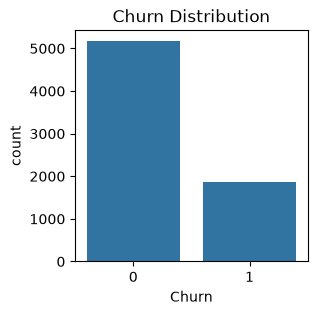

In [32]:
plt.figure(figsize=(3, 3))
sns.countplot(data=df, x="Churn")
plt.title("Churn Distribution")
plt.show()

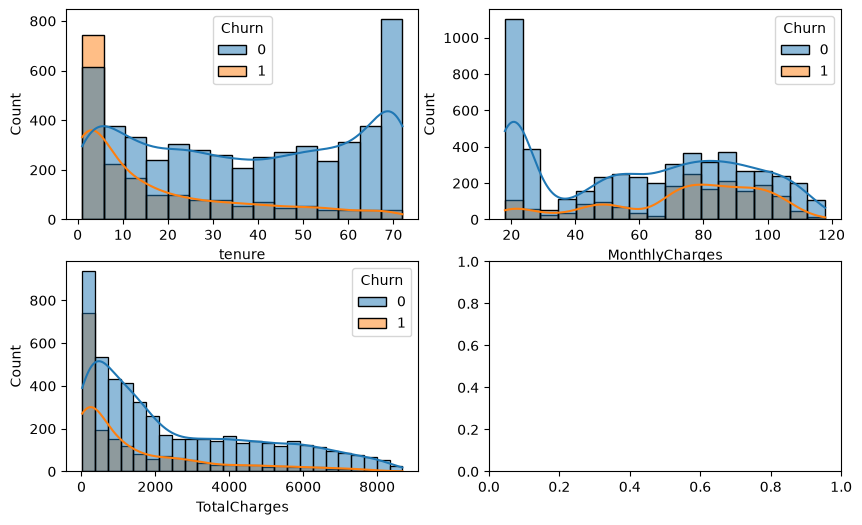

In [26]:
numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
f,axis=plt.subplots(2,2, figsize=(10,6))
for i, col in enumerate(numeric_cols):
    sns.histplot(data=df, x=col, ax=axis[i//2,i%2],kde=True,hue="Churn")

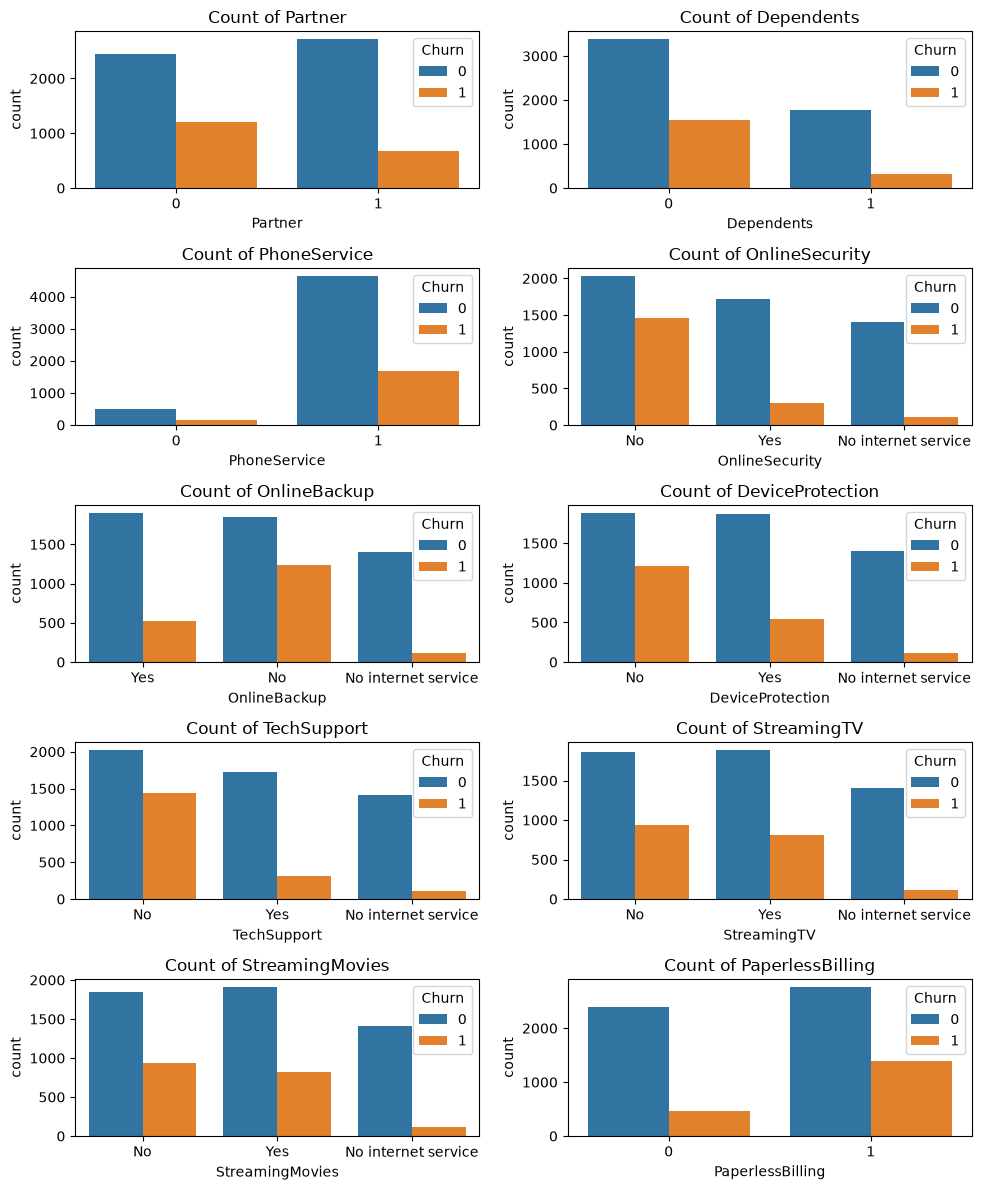

In [ ]:
col=['Partner','Dependents','PhoneService','OnlineSecurity','OnlineBackup','DeviceProtection','TechSupport','StreamingTV','StreamingMovies','PaperlessBilling']
cols = [
    'SeniorCitizen', 'Partner', 'Dependents',
    'PhoneService', 'PaperlessBilling'
]
fig, ax = plt.subplots(5, 2, figsize=(10, 12))
ax = ax.flatten()

for i, col in enumerate(col):
    sns.countplot(data=df, x=col,hue='Churn', ax=ax[i])
    ax[i].set_title(f"Count of {col}")
#ax[-1].set_visible(False)  # Hide unused sixth subplot

plt.tight_layout()
plt.show()

In [ ]:
pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
).mul(100).round(2)

Churn,0,1
Contract,,
Month-to-month,57.29,42.71
One year,88.72,11.28
Two year,97.15,2.85


In [ ]:
col=["TotalCharges","MonthlyCharges","tenure"]
corr=df[col].corr()
corr

,TotalCharges,MonthlyCharges,tenure
TotalCharges,1.000000,0.651126,0.825880
MonthlyCharges,0.651126,1.000000,0.246876
tenure,0.825880,0.246876,1.000000


In [ ]:
summary = df.groupby("Churn").agg(
    Customer_Count=("Churn", "size"),
    Avg_Tenure=("tenure", "mean"),
    Median_Tenure=("tenure", "median"),
    Avg_Monthly_Charges=("MonthlyCharges", "mean"),
    Avg_Total_Charges=("TotalCharges", "mean")
).round(2)

summary

,Customer_Count,Avg_Tenure,Median_Tenure,Avg_Monthly_Charges,Avg_Total_Charges
Churn,,,,,
0,5163,37.65,38.0,60.84,2555.34
1,1869,17.98,10.0,73.98,1531.80


In [ ]:
df["tenur"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0–12 months", "13–24 months",
            "25–48 months", "49–72 months"]
)
tenure_churn = (
    df.groupby("tenur", observed=True)["Churn"]
      .apply(lambda x: x.eq(1).mean() * 100)
      .round(2)
)

print(tenure_churn)

tenur
0–12 months     47.68
13–24 months    28.71
25–48 months    20.39
49–72 months     9.51
Name: Churn, dtype: float64


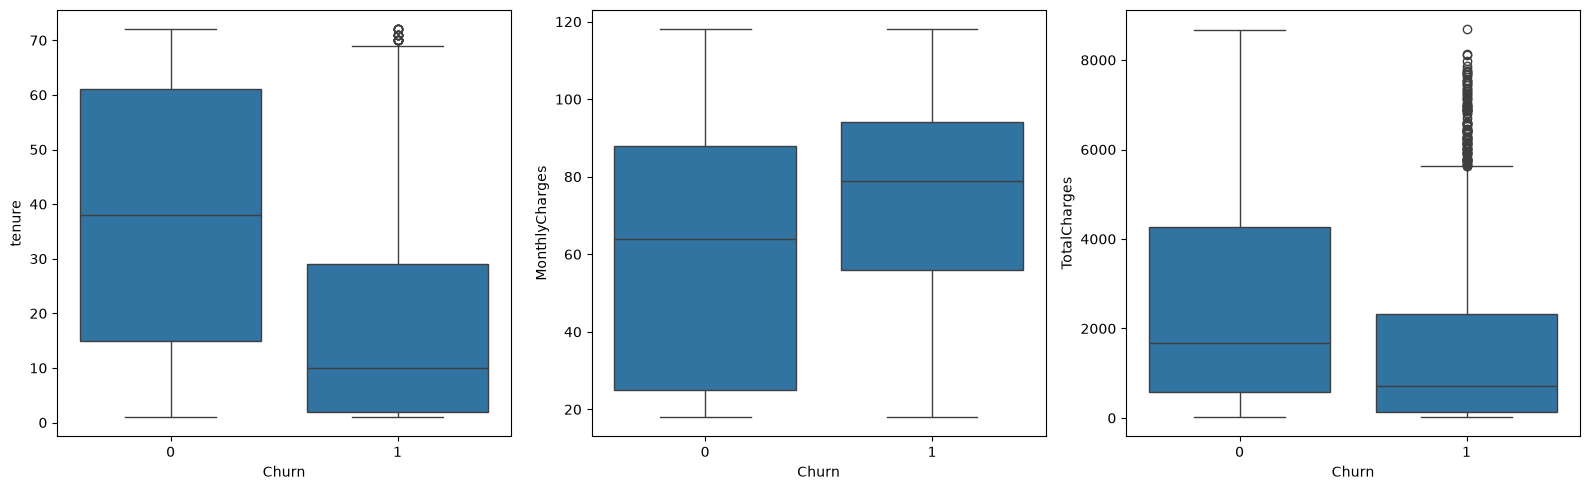

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.boxplot(data=df, x="Churn", y="tenure", ax=axes[0])
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=axes[1])
sns.boxplot(data=df, x="Churn", y="TotalCharges", ax=axes[2])

plt.tight_layout()
plt.show()


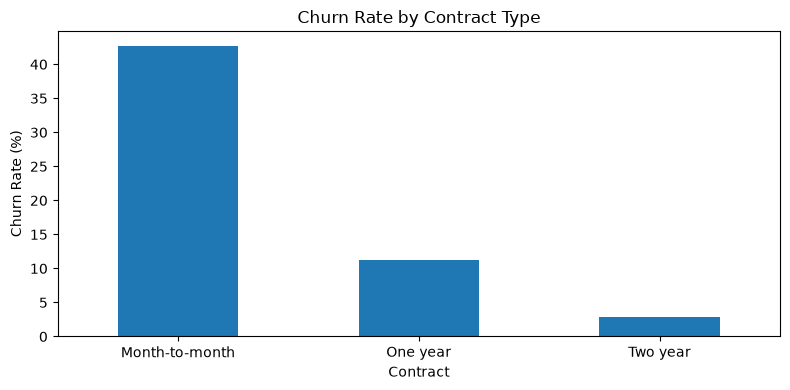

In [ ]:

churn_rates = (
    df.groupby("Contract", observed=True)["Churn"]
      .apply(lambda x: (x == 1).mean() * 100)
      .sort_values(ascending=False)
)
churn_rates.plot(kind="bar", figsize=(8, 4))
plt.title("Churn Rate by Contract Type")
plt.ylabel("Churn Rate (%)")
plt.xlabel("Contract")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [ ]:

import os

print(os.getcwd())


D:\project\New folder\New folder\telco-customer-churn-prediction\notebook
